<a href="https://colab.research.google.com/github/ClassNeuralNetwork/Skin-Disease-Dataset/blob/main/EficientNETB0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [25]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import kagglehub
import random
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from PIL import Image
from collections import Counter
from sklearn.metrics import classification_report

In [9]:
import kagglehub
import os

# Baixando o novo dataset de doenças de pele
skin_path = kagglehub.dataset_download("pacificrm/skindiseasedataset")

print("Caminho do dataset de pele:", skin_path)
print("\nConteúdo encontrado:")
print(os.listdir(skin_path))

Using Colab cache for faster access to the 'skindiseasedataset' dataset.
Caminho do dataset de pele: /kaggle/input/skindiseasedataset

Conteúdo encontrado:
['SkinDisease', 'Readme.md']


In [10]:
import kagglehub
import os

# Garante o download do dataset de doenças de pele
skin_path = kagglehub.dataset_download("pacificrm/skindiseasedataset")
skin_data_dir = skin_path

print("Conteúdo do diretório principal:")
for item in sorted(os.listdir(skin_data_dir)):
    item_path = os.path.join(skin_data_dir, item)
    if os.path.isdir(item_path):
        sub_items = os.listdir(item_path)
        print(f"{item}/ (pasta) - {len(sub_items)} itens")
    else:
        print(f"{item} (arquivo)")

Using Colab cache for faster access to the 'skindiseasedataset' dataset.
Conteúdo do diretório principal:
Readme.md (arquivo)
SkinDisease/ (pasta) - 1 itens


In [11]:
sub_path = os.path.join(skin_data_dir, "SkinDisease")
print("Conteúdo da pasta 'SkinDisease':")
for item in sorted(os.listdir(sub_path)):
    item_path = os.path.join(sub_path, item)
    if os.path.isdir(item_path):
        sub_items = os.listdir(item_path)
        print(f"{item}/ (pasta) - {len(sub_items)} itens")
    else:
        print(f"{item} (arquivo)")

Conteúdo da pasta 'SkinDisease':
SkinDisease/ (pasta) - 2 itens


In [12]:
import os

# Definir caminhos para treino e teste no novo dataset de doenças de pele
skin_train_dir = os.path.join(sub_path, "SkinDisease", "train")
skin_test_dir = os.path.join(sub_path, "SkinDisease", "test")

print("Classes no diretório de treino:")
for item in sorted(os.listdir(skin_train_dir)):
    path_item = os.path.join(skin_train_dir, item)
    if os.path.isdir(path_item):
        print(f"{item}: {len(os.listdir(path_item))} imagens")

Classes no diretório de treino:
Acne: 593 imagens
Actinic_Keratosis: 748 imagens
Benign_tumors: 1093 imagens
Bullous: 504 imagens
Candidiasis: 248 imagens
DrugEruption: 547 imagens
Eczema: 1010 imagens
Infestations_Bites: 524 imagens
Lichen: 553 imagens
Lupus: 311 imagens
Moles: 361 imagens
Psoriasis: 820 imagens
Rosacea: 254 imagens
Seborrh_Keratoses: 455 imagens
SkinCancer: 693 imagens
Sun_Sunlight_Damage: 312 imagens
Tinea: 923 imagens
Unknown_Normal: 1651 imagens
Vascular_Tumors: 543 imagens
Vasculitis: 461 imagens
Vitiligo: 714 imagens
Warts: 580 imagens


In [13]:
import os
import shutil

# Definindo caminhos originais
skin_train_dir = os.path.join(sub_path, "SkinDisease", "train")
skin_test_dir = os.path.join(sub_path, "SkinDisease", "test")

# Criando caminhos temporários para os dados filtrados
filtered_train_dir = "/tmp/skin_train_filtered"
filtered_test_dir = "/tmp/skin_test_filtered"

os.makedirs(filtered_train_dir, exist_ok=True)
os.makedirs(filtered_test_dir, exist_ok=True)

# Função para copiar todas as pastas exceto 'Unknown_Normal'
def copiar_dados_filtrados(src, dst):
    for classe in os.listdir(src):
        if classe == "Unknown_Normal":
            continue
        caminho_origem = os.path.join(src, classe)
        caminho_destino = os.path.join(dst, classe)
        if os.path.isdir(caminho_origem):
            if os.path.exists(caminho_destino):
                shutil.rmtree(caminho_destino)
            shutil.copytree(caminho_origem, caminho_destino)

copiar_dados_filtrados(skin_train_dir, filtered_train_dir)
copiar_dados_filtrados(skin_test_dir, filtered_test_dir)

print("Filtros aplicados! 'Unknown_Normal' foi removido.")
print("Classes restantes:", len(os.listdir(filtered_train_dir)))

Filtros aplicados! 'Unknown_Normal' foi removido.
Classes restantes: 21


In [14]:
import tensorflow as tf

SEED = 42
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

# Dicionário de tradução das classes para o português
traducao_classes = {
    'Acne': 'Acne',
    'Actinic_Keratosis': 'Ceratose_Actinica',
    'Benign_tumors': 'Tumores_Benignos',
    'Bullous': 'Doencas_Bolhosas',
    'Candidiasis': 'Candidiase',
    'DrugEruption': 'Farmacodermia',
    'Eczema': 'Eczema',
    'Infestations_Bites': 'Infestacoes_e_Picadas',
    'Lichen': 'Liquen',
    'Lupus': 'Lupus',
    'Moles': 'Sinais_Nevos',
    'Psoriasis': 'Psoriase',
    'Rosacea': 'Rosacea',
    'Seborrh_Keratoses': 'Ceratose_Seborreica',
    'SkinCancer': 'Cancer_de_Pele',
    'Sun_Sunlight_Damage': 'Dano_Solar',
    'Tinea': 'Tinha_Micose',
    'Vascular_Tumors': 'Tumores_Vasculares',
    'Vasculitis': 'Vasculite',
    'Vitiligo': 'Vitiligo',
    'Warts': 'Verrugas'
}

# Carregando os conjuntos de dados sem a classe indesejada
skin_train_ds = tf.keras.utils.image_dataset_from_directory(
    filtered_train_dir,
    validation_split=0.20,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="int",
    shuffle=True
)

skin_val_ds = tf.keras.utils.image_dataset_from_directory(
    filtered_train_dir,
    validation_split=0.20,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="int",
    shuffle=False
)

skin_test_ds = tf.keras.utils.image_dataset_from_directory(
    filtered_test_dir,
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="int",
    shuffle=False
)

# Obtendo as classes originais e mapeando para o português
classes_originais = skin_train_ds.class_names
classes_portugues = [traducao_classes.get(nome, nome) for nome in classes_originais]

print("\nTotal de classes ativas:", len(classes_originais))
print("Classes traduzidas:", classes_portugues)

Found 12247 files belonging to 21 classes.
Using 9798 files for training.
Found 12247 files belonging to 21 classes.
Using 2449 files for validation.
Found 1357 files belonging to 21 classes.

Total de classes ativas: 21
Classes traduzidas: ['Acne', 'Ceratose_Actinica', 'Tumores_Benignos', 'Doencas_Bolhosas', 'Candidiase', 'Farmacodermia', 'Eczema', 'Infestacoes_e_Picadas', 'Liquen', 'Lupus', 'Sinais_Nevos', 'Psoriase', 'Rosacea', 'Ceratose_Seborreica', 'Cancer_de_Pele', 'Dano_Solar', 'Tinha_Micose', 'Tumores_Vasculares', 'Vasculite', 'Vitiligo', 'Verrugas']


In [15]:
AUTOTUNE = tf.data.AUTOTUNE

# EfficientNetB0 realiza o redimensionamento e normalização internamente dentro do modelo.
# Apenas convertemos a imagem para float32 sem aplicar pré-processamento de subtração de média.
def preparar_para_efficientnet(imagens, rotulos):
    imagens = tf.cast(imagens, tf.float32)
    return imagens, rotulos

skin_train_ds = skin_train_ds.map(preparar_para_efficientnet, num_parallel_calls=AUTOTUNE)
skin_val_ds = skin_val_ds.map(preparar_para_efficientnet, num_parallel_calls=AUTOTUNE)
skin_test_ds = skin_test_ds.map(preparar_para_efficientnet, num_parallel_calls=AUTOTUNE)

skin_train_ds = skin_train_ds.prefetch(AUTOTUNE)
skin_val_ds = skin_val_ds.prefetch(AUTOTUNE)
skin_test_ds = skin_test_ds.prefetch(AUTOTUNE)

print("Pipeline de dados otimizado para EfficientNetB0!")

Pipeline de dados otimizado para EfficientNetB0!


In [16]:
import os
import shutil

# Caminhos originais
skin_train_dir = os.path.join(sub_path, "SkinDisease", "train")
skin_test_dir = os.path.join(sub_path, "SkinDisease", "test")

# Criando diretórios filtrados para excluir 'Unknown_Normal'
filtered_train_dir = "/tmp/skin_train_filtered"
filtered_test_dir = "/tmp/skin_test_filtered"

os.makedirs(filtered_train_dir, exist_ok=True)
os.makedirs(filtered_test_dir, exist_ok=True)

# Função para copiar as classes exceto 'Unknown_Normal'
def copiar_classes_filtradas(src_dir, dst_dir):
    for class_name in os.listdir(src_dir):
        if class_name == "Unknown_Normal":
            continue
        src_class_path = os.path.join(src_dir, class_name)
        dst_class_path = os.path.join(dst_dir, class_name)
        if os.path.isdir(src_class_path):
            if os.path.exists(dst_class_path):
                shutil.rmtree(dst_class_path)
            shutil.copytree(src_class_path, dst_class_path)

copiar_classes_filtradas(skin_train_dir, filtered_train_dir)
copiar_classes_filtradas(skin_test_dir, filtered_test_dir)

print("Diretórios filtrados criados sem 'Unknown_Normal'.")
print("Classes no novo treino:", sorted(os.listdir(filtered_train_dir)))

Diretórios filtrados criados sem 'Unknown_Normal'.
Classes no novo treino: ['Acne', 'Actinic_Keratosis', 'Benign_tumors', 'Bullous', 'Candidiasis', 'DrugEruption', 'Eczema', 'Infestations_Bites', 'Lichen', 'Lupus', 'Moles', 'Psoriasis', 'Rosacea', 'Seborrh_Keratoses', 'SkinCancer', 'Sun_Sunlight_Damage', 'Tinea', 'Vascular_Tumors', 'Vasculitis', 'Vitiligo', 'Warts']


In [17]:
import tensorflow as tf

SEED = 42
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

# Carregando dados de Treino e Validação a partir do diretório filtrado
skin_train_ds = tf.keras.utils.image_dataset_from_directory(
    filtered_train_dir,
    validation_split=0.20,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="int",
    shuffle=True
)

skin_val_ds = tf.keras.utils.image_dataset_from_directory(
    filtered_train_dir,
    validation_split=0.20,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="int",
    shuffle=False
)

# Conjunto de testes pré-definido filtrado
skin_test_ds = tf.keras.utils.image_dataset_from_directory(
    filtered_test_dir,
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="int",
    shuffle=False
)

# Usando diretamente as classes originais em inglês
skin_class_names = skin_train_ds.class_names

print("Total de Classes:", len(skin_class_names))
print("Classes originais:", skin_class_names)

Found 12247 files belonging to 21 classes.
Using 9798 files for training.
Found 12247 files belonging to 21 classes.
Using 2449 files for validation.
Found 1357 files belonging to 21 classes.
Total de Classes: 21
Classes originais: ['Acne', 'Actinic_Keratosis', 'Benign_tumors', 'Bullous', 'Candidiasis', 'DrugEruption', 'Eczema', 'Infestations_Bites', 'Lichen', 'Lupus', 'Moles', 'Psoriasis', 'Rosacea', 'Seborrh_Keratoses', 'SkinCancer', 'Sun_Sunlight_Damage', 'Tinea', 'Vascular_Tumors', 'Vasculitis', 'Vitiligo', 'Warts']


In [18]:
AUTOTUNE = tf.data.AUTOTUNE

# EfficientNetB0 espera valores de pixel no intervalo [0, 255] pois possui a normalização internamente
def preparar_skin_imagens_efficientnet(imagens, rotulos):
    # Apenas garantimos que os dados estão no tipo float32 sem aplicar o preprocess_input da ResNet
    imagens = tf.cast(imagens, tf.float32)
    return imagens, rotulos

skin_train_ds = skin_train_ds.map(preparar_skin_imagens_efficientnet, num_parallel_calls=AUTOTUNE)
skin_val_ds = skin_val_ds.map(preparar_skin_imagens_efficientnet, num_parallel_calls=AUTOTUNE)
skin_test_ds = skin_test_ds.map(preparar_skin_imagens_efficientnet, num_parallel_calls=AUTOTUNE)

skin_train_ds = skin_train_ds.prefetch(AUTOTUNE)
skin_val_ds = skin_val_ds.prefetch(AUTOTUNE)
skin_test_ds = skin_test_ds.prefetch(AUTOTUNE)

print("Preparação de imagens para EfficientNet concluída.")

Preparação de imagens para EfficientNet concluída.


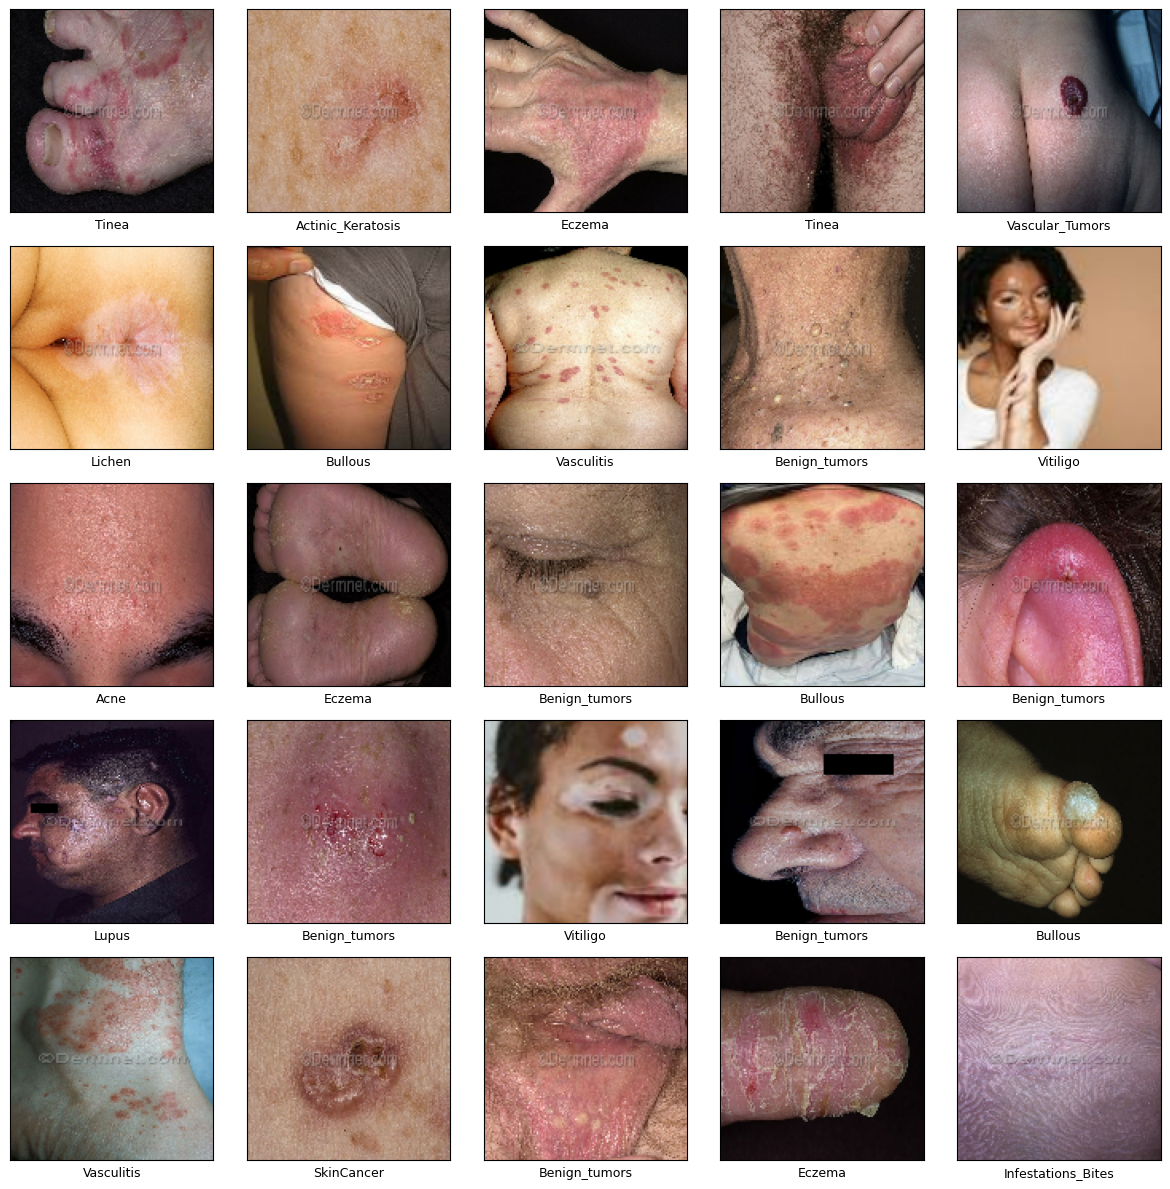

In [19]:
import matplotlib.pyplot as plt

# Extrair um lote de imagens para visualização
for imagens, rotulos in skin_train_ds.take(1):
    plt.figure(figsize=(12, 12))
    for i in range(min(25, len(imagens))):
        plt.subplot(5, 5, i + 1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)

        # Converter a imagem de volta de float32 para o formato de exibição
        img = imagens[i].numpy().astype("uint8")
        plt.imshow(img)

        # Obter o rótulo correspondente utilizando os nomes originais em inglês
        classe_idx = int(rotulos[i].numpy())
        classe_nome = skin_class_names[classe_idx]
        plt.xlabel(classe_nome, fontsize=9)

    plt.tight_layout()
    plt.show()

In [20]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam

# Carregando o modelo EfficientNetB0 pré-treinado
skin_base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(128, 128, 3)
)

# Congelando os pesos do modelo base
skin_base_model.trainable = False

# Definindo a nova arquitetura para as 21 classes restantes com EfficientNetB0
skin_model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    skin_base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(21, activation="softmax")  # 21 classes após remoção do Unknown_Normal
])

skin_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

skin_model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 4, 4, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 21)             │         5,397 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,382,904 (16.72 MB)

 Trainable params: 333,333 (1.27 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [21]:
skin_early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Iniciando o treinamento do modelo de doenças de pele
skin_history = skin_model.fit(
    skin_train_ds,
    validation_data=skin_val_ds,
    epochs=15,
    callbacks=[skin_early_stop]
)

Epoch 1/15
307/307 ━━━━━━━━━━━━━━━━━━━━ 336s 1s/step - accuracy: 0.2854 - loss: 2.3991 - val_accuracy: 0.5010 - val_loss: 1.6339
Epoch 2/15
307/307 ━━━━━━━━━━━━━━━━━━━━ 323s 1s/step - accuracy: 0.3913 - loss: 1.9935 - val_accuracy: 0.5476 - val_loss: 1.4741
Epoch 3/15
307/307 ━━━━━━━━━━━━━━━━━━━━ 314s 1s/step - accuracy: 0.4421 - loss: 1.8055 - val_accuracy: 0.5962 - val_loss: 1.3250
Epoch 4/15
307/307 ━━━━━━━━━━━━━━━━━━━━ 316s 1s/step - accuracy: 0.4866 - loss: 1.6490 - val_accuracy: 0.6525 - val_loss: 1.1584
Epoch 5/15
307/307 ━━━━━━━━━━━━━━━━━━━━ 328s 1s/step - accuracy: 0.5220 - loss: 1.5217 - val_accuracy: 0.7036 - val_loss: 1.0369
Epoch 6/15
307/307 ━━━━━━━━━━━━━━━━━━━━ 319s 1s/step - accuracy: 0.5532 - loss: 1.4284 - val_accuracy: 0.7317 - val_loss: 0.9578
Epoch 7/15
307/307 ━━━━━━━━━━━━━━━━━━━━ 308s 1s/step - accuracy: 0.5760 - loss: 1.3460 - val_accuracy: 0.7472 - val_loss: 0.8900
Epoch 8/15
307/307 ━━━━━━━━━━━━━━━━━━━━ 296s 964ms/step - accuracy: 0.6012 - loss: 1.2611 - val_a

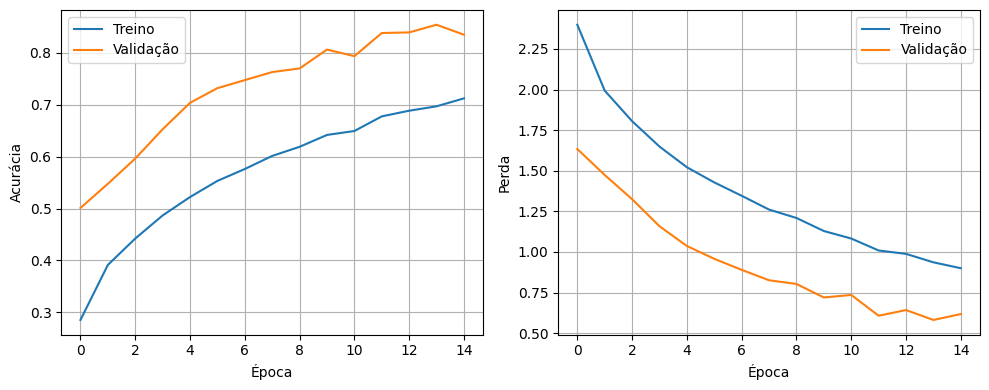

43/43 - 32s - 742ms/step - accuracy: 0.5269 - loss: 1.6451

Acurácia no conjunto de teste: 52.69%


In [22]:
import matplotlib.pyplot as plt

# Gerando os gráficos de desempenho do treinamento
plt.figure(figsize=(10, 4))

# Gráfico de Acurácia
plt.subplot(1, 2, 1)
plt.plot(skin_history.history['accuracy'], label='Treino')
plt.plot(skin_history.history['val_accuracy'], label='Validação')
plt.xlabel('Época')
plt.ylabel('Acurácia')
plt.legend(loc='best')
plt.grid(True)

# Gráfico de Perda (Loss)
plt.subplot(1, 2, 2)
plt.plot(skin_history.history['loss'], label='Treino')
plt.plot(skin_history.history['val_loss'], label='Validação')
plt.xlabel('Época')
plt.ylabel('Perda')
plt.legend(loc='best')
plt.grid(True)

plt.tight_layout()
plt.show()

# Avaliação final no conjunto de teste estruturado
test_loss, test_acc = skin_model.evaluate(skin_test_ds, verbose=2)
print(f"\nAcurácia no conjunto de teste: {test_acc * 100:.2f}%")

In [23]:
# Avaliando o modelo no conjunto de teste independente de doenças de pele
skin_test_loss, skin_test_accuracy = skin_model.evaluate(skin_test_ds)

print(f"\nPerda no Teste (Skin Disease): {skin_test_loss:.4f}")
print(f"Acurácia no Teste (Skin Disease): {skin_test_accuracy * 100:.2f}%")

43/43 ━━━━━━━━━━━━━━━━━━━━ 33s 766ms/step - accuracy: 0.5269 - loss: 1.6451

Perda no Teste (Skin Disease): 1.6451
Acurácia no Teste (Skin Disease): 52.69%


43/43 ━━━━━━━━━━━━━━━━━━━━ 37s 795ms/step
=== RELATÓRIO DE CLASSIFICAÇÃO (Skin Disease) ===
                     precision    recall  f1-score   support

               Acne     0.7258    0.6923    0.7087        65
  Actinic_Keratosis     0.4592    0.5422    0.4972        83
      Benign_tumors     0.4540    0.6529    0.5356       121
            Bullous     0.5357    0.5455    0.5405        55
        Candidiasis     0.7143    0.3704    0.4878        27
       DrugEruption     0.6667    0.4918    0.5660        61
             Eczema     0.4874    0.5179    0.5022       112
 Infestations_Bites     0.4815    0.4333    0.4561        60
             Lichen     0.5122    0.3443    0.4118        61
              Lupus     0.2727    0.1765    0.2143        34
              Moles     0.6364    0.3500    0.4516        40
          Psoriasis     0.4762    0.5682    0.5181        88
            Rosacea     0.4872    0.6786    0.5672        28
  Seborrh_Keratoses     0.7368    0.5490    0.6292   

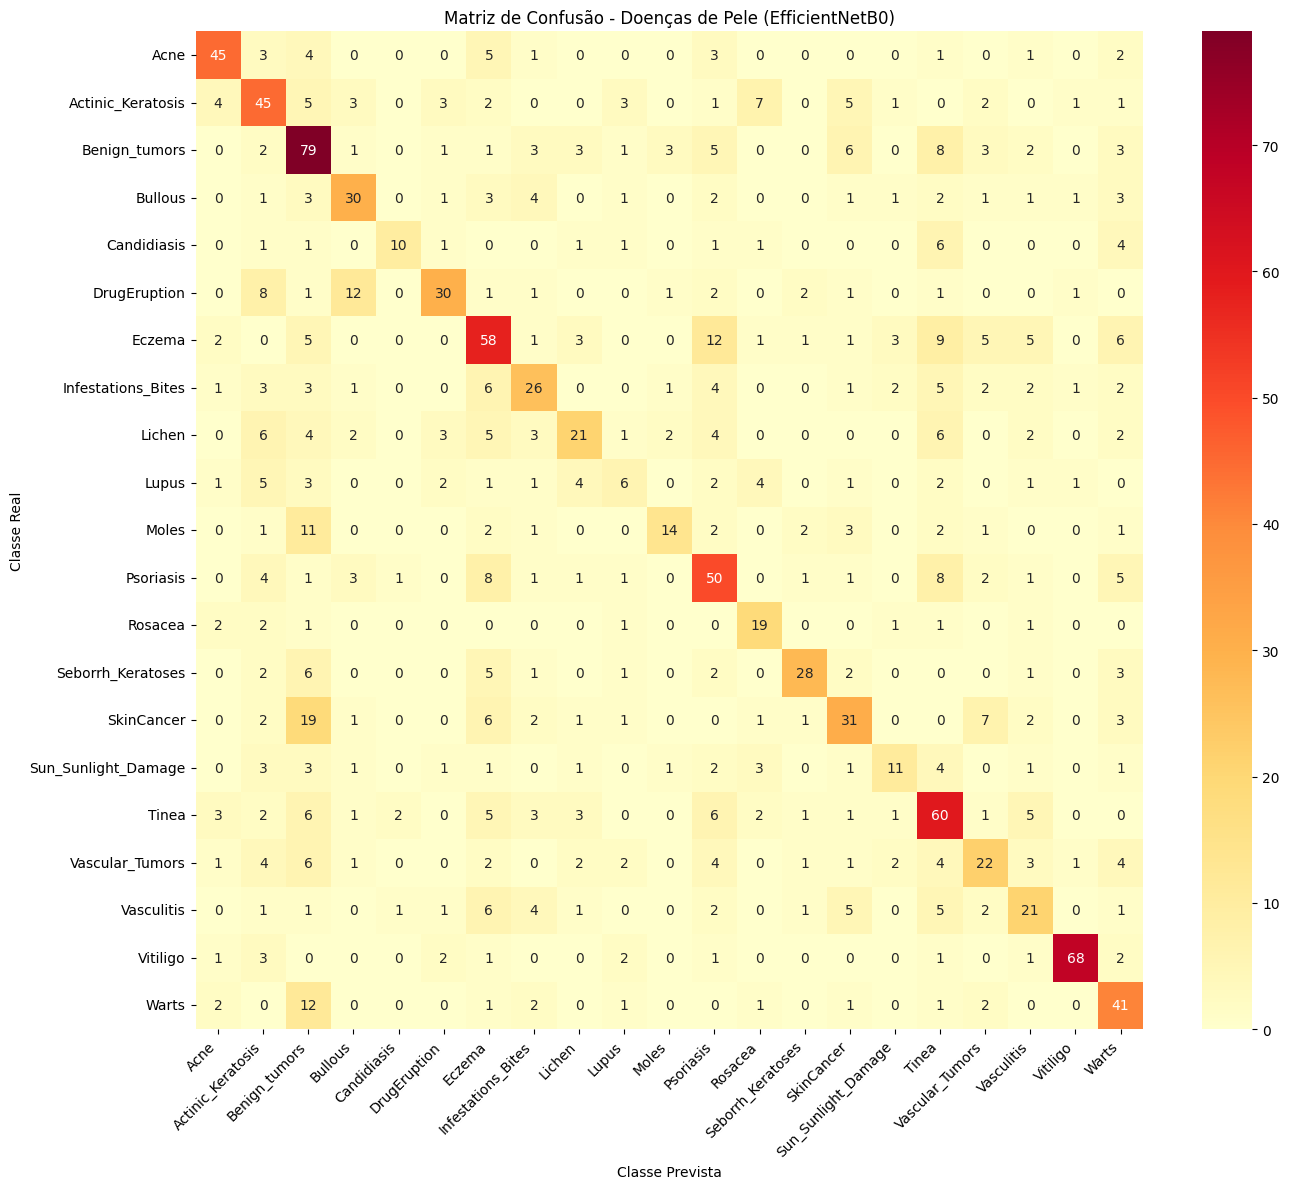

In [24]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Extrair rótulos reais do conjunto de teste
y_true_skin = np.concatenate([labels.numpy() for _, labels in skin_test_ds])

# Realizar as previsões
y_prob_skin = skin_model.predict(skin_test_ds)
y_pred_skin = np.argmax(y_prob_skin, axis=1)

# Relatório de classificação detalhado com classes em inglês
print("=== RELATÓRIO DE CLASSIFICAÇÃO (Skin Disease) ===")
print(classification_report(
    y_true_skin,
    y_pred_skin,
    target_names=skin_class_names,
    digits=4
))

# Matriz de Confusão com classes em inglês
cm_skin = confusion_matrix(y_true_skin, y_pred_skin)

plt.figure(figsize=(14, 12))
sns.heatmap(
    cm_skin,
    annot=True,
    fmt="d",
    cmap="YlOrRd",
    xticklabels=skin_class_names,
    yticklabels=skin_class_names
)

plt.title("Matriz de Confusão - Doenças de Pele (EfficientNetB0)")
plt.xlabel("Classe Prevista")
plt.ylabel("Classe Real")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Nova seção